# Telecom Customer Churn Prediction 

## 1. Imports and load data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay)
from xgboost import XGBClassifier

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_path = project_root / 'data' / 'processed' / 'customer_features.csv'
models_dir = project_root / 'models'
models_dir.mkdir(exist_ok=True, parents=True)

df = pd.read_csv(data_path)
print('Shape:', df.shape)
print('Churn rate:', round(df['churn'].mean() * 100, 2), '%')
display(df.head())

Shape: (10000, 38)
Churn rate: 7.86 %


,customer_id,age,gender,region,contract_type,monthly_charges,age_missing,tenure_months,signed_up_after_window_start,call_minutes_mean,...,sms_count_recent_vs_early,sms_count_cv,complaints_total,complaints_mean,complaint_months,complaints_recent3,active_months,data_gb_per_charge,minutes_per_charge,churn
0,CUST_0,NaN,Male,Urban,Yearly,48.18,1,33,0,493.412222,...,1.482759,0.459933,6,0.666667,5,0,9,0.192726,10.241017,0
1,CUST_1,NaN,Female,Suburban,Prepaid,38.94,1,47,0,457.194444,...,0.882979,0.443321,8,0.888889,6,2,9,0.258945,11.740998,0
2,CUST_10,NaN,Female,Urban,Prepaid,47.81,1,20,0,617.418889,...,0.545455,0.646542,11,1.222222,7,5,9,0.172000,12.914011,0
3,CUST_100,62.0,Female,Urban,Monthly,29.80,0,26,0,529.485556,...,1.337662,0.429875,5,0.555556,5,2,9,0.306152,17.767972,0
4,CUST_1000,NaN,Female,Suburban,Monthly,61.62,1,67,0,506.097778,...,0.290323,0.635269,10,1.111111,7,4,9,0.174709,8.213206,0


## 2. Prepare features and train/test split

Keep the test set untouched until final evaluation. Stratification maintains approximately the same churn proportion in both splits.

In [2]:
X = df.drop(columns=['customer_id', 'churn'])
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Numeric:', len(numeric_cols), '| Categorical:', categorical_cols)

Train: (8000, 36) | Test: (2000, 36)
Numeric: 33 | Categorical: ['gender', 'region', 'contract_type']


## 3. Preprocessing

The preprocessing is **inside** each model pipeline, so it is fitted only on the training portion of each CV fold. Missing values are imputed, numerical features are scaled, and categorical features are one-hot encoded.

In [3]:
numeric_steps = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_steps = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_steps, numeric_cols),
    ('categorical', categorical_steps, categorical_cols)
])

## 4. Train and compare models with 5-fold CV

**Average Precision (AP)** is the main selection metric because churn is an imbalanced class. CV runs on training data only.

In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=10,
                                            class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                              eval_metric='logloss', random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, classifier in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', classifier)])
    ap = cross_val_score(pipeline, X_train, y_train, cv=cv,
                         scoring='average_precision', n_jobs=1)
    auc = cross_val_score(pipeline, X_train, y_train, cv=cv,
                          scoring='roc_auc', n_jobs=1)
    results.append({'Model': name, 'CV AP': ap.mean(), 'CV ROC-AUC': auc.mean()})

cv_results = pd.DataFrame(results).sort_values('CV AP', ascending=False)
display(cv_results.round(4))
print('Training churn baseline (AP reference):', round(y_train.mean(), 4))

,Model,CV AP,CV ROC-AUC
2,XGBoost,0.0909,0.5236
1,Random Forest,0.0871,0.5136
0,Logistic Regression,0.0826,0.4992


Training churn baseline (AP reference): 0.0786


The model is chosen using training CV only. We then use out-of-fold predictions from the training set to choose a threshold that maximizes F1. The test set remains untouched until final evaluation.


In [5]:
best_name = cv_results.iloc[0]['Model']
best_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', models[best_name])
])

# Choose a threshold using out-of-fold predictions from the training set only.
# Each training row is predicted by a model that did not train on that row.
oof_probabilities = cross_val_predict(
    best_pipeline, X_train, y_train,
    cv=cv, method='predict_proba', n_jobs=1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_probabilities)
f1_scores = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]

# Fit the selected pipeline on all training data and evaluate once on the test set.
best_pipeline.fit(X_train, y_train)
probabilities = best_pipeline.predict_proba(X_test)[:, 1]
predictions = (probabilities >= best_threshold).astype(int)

print('Selected model:', best_name)
print('Selected threshold (training CV):', round(float(best_threshold), 4))
print('Test ROC-AUC:', round(roc_auc_score(y_test, probabilities), 4))
print('Test Average Precision:', round(average_precision_score(y_test, probabilities), 4))
print('Test churn baseline:', round(y_test.mean(), 4))
print('Confusion matrix:\n', confusion_matrix(y_test, predictions))
print('\nClassification report:\n', classification_report(y_test, predictions, zero_division=0))


Selected model: XGBoost
Selected threshold (training CV): 0.0524
Test ROC-AUC: 0.4741
Test Average Precision: 0.0756
Test churn baseline: 0.0785
Confusion matrix:
 [[ 396 1447]
 [  38  119]]

Classification report:
               precision    recall  f1-score   support

           0       0.91      0.21      0.35      1843
           1       0.08      0.76      0.14       157

    accuracy                           0.26      2000
   macro avg       0.49      0.49      0.24      2000
weighted avg       0.85      0.26      0.33      2000



## 6. ROC and Precision–Recall curves

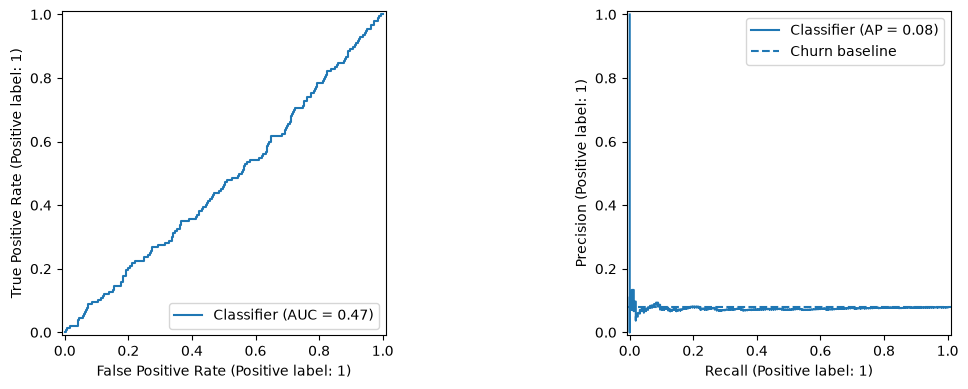

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, probabilities, ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle='--', label='Churn baseline')
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Save the model

The saved pipeline accepts the same raw feature columns used during training. For future customers, match these columns and use only information known at prediction time.

In [7]:
model_path = models_dir / 'churn_pipeline.joblib'
joblib.dump(best_pipeline, model_path)
print('Saved:', model_path)
print('Remember to use this threshold for classification:', round(float(best_threshold), 4))
print('Expected input columns:', X_train.columns.tolist())

Saved: d:\Ahmed\My Projects\telecom intelligence project\models\churn_pipeline.joblib
Remember to use this threshold for classification: 0.0524
Expected input columns: ['age', 'gender', 'region', 'contract_type', 'monthly_charges', 'age_missing', 'tenure_months', 'signed_up_after_window_start', 'call_minutes_mean', 'call_minutes_std', 'call_minutes_min', 'call_minutes_max', 'call_minutes_slope', 'call_minutes_recent_vs_early', 'call_minutes_cv', 'data_usage_gb_mean', 'data_usage_gb_std', 'data_usage_gb_min', 'data_usage_gb_max', 'data_usage_gb_slope', 'data_usage_gb_recent_vs_early', 'data_usage_gb_cv', 'sms_count_mean', 'sms_count_std', 'sms_count_min', 'sms_count_max', 'sms_count_slope', 'sms_count_recent_vs_early', 'sms_count_cv', 'complaints_total', 'complaints_mean', 'complaint_months', 'complaints_recent3', 'active_months', 'data_gb_per_charge', 'minutes_per_charge']


- **ROC-AUC near 0.5** means the model barely ranks churners above non-churners.
- **AP near the churn prevalence** means little improvement over a random ranking baseline.
- The classification threshold is selected by maximizing F1 on out-of-fold predictions from the training set; the test set is not used to choose it.
- Threshold tuning changes the precision/recall trade-off; it does not improve the underlying ranking ability measured by ROC-AUC or Average Precision.
- **Probabilities are not calibrated here.** Do not interpret them as validated real-world churn risks or use them to estimate financial loss without further validation.
- The split is **random stratified, not temporal**. If you have dated snapshots and a future churn outcome, a time-based split is preferable.
- Do not use actual `churn` labels to calculate customer retention priority. A retention workflow requires trustworthy out-of-sample predictions and appropriate validation.
- If performance remains close to random, report this limitation openly rather than claiming successful churn prediction.
